# TARANG: Edge Coupler Module Examples

In [ ]:
# ---- Logging ---- #
from tarang import configure_logging, set_tidy3d_output

configure_logging(level="INFO")  # Show programmer-written TARANG logs
set_tidy3d_output(False)         # Suppress Tidy3D chatter and managed progress bars

# ---- Define Media ---- #
from media import get_medium, get_medium_dispersion

# 1) PECDV SiN Data
Si3N4 = get_medium(
    medium_key = "si3n4",
    wl_range = (1.550 - 0.200, 1.550 + 0.200),
    tolerance = 1e-5
)

# 2) Silica
SiO2 = get_medium(
    medium_key = "sio2",
    wl_range = (1.550 - 0.200, 1.550 + 0.200),
    tolerance = 5e-5
)

2026-09-06 17:25:25,659 - media.medium_helper - INFO - [Medium] Cache HIT for si3n4. Reusing Luke_Si3N4_737c6e77.json (Fit range: [1.35, 1.75], RMS: 2.66e-15, Poles allowed: 10).
2026-09-06 17:25:25,661 - media.medium_helper - INFO - [Medium] Cache HIT for sio2. Reusing Nyakuchena_fusedSilica_78358b24.json (Fit range: [1.35, 1.75], RMS: 1.32e-05, Poles allowed: 10).


## Edge Coupler: Example Geometry

2026-09-06 17:25:28,311 - media.medium_helper - INFO - [Medium] Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...
2026-09-06 17:25:28,312 - media.medium_helper - INFO - [Medium] Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...
2026-09-06 17:25:28,313 - media.medium_helper - INFO - [Medium] Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...
2026-09-06 17:25:29,442 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/edge_coupler/example_edge__out_coupler.png


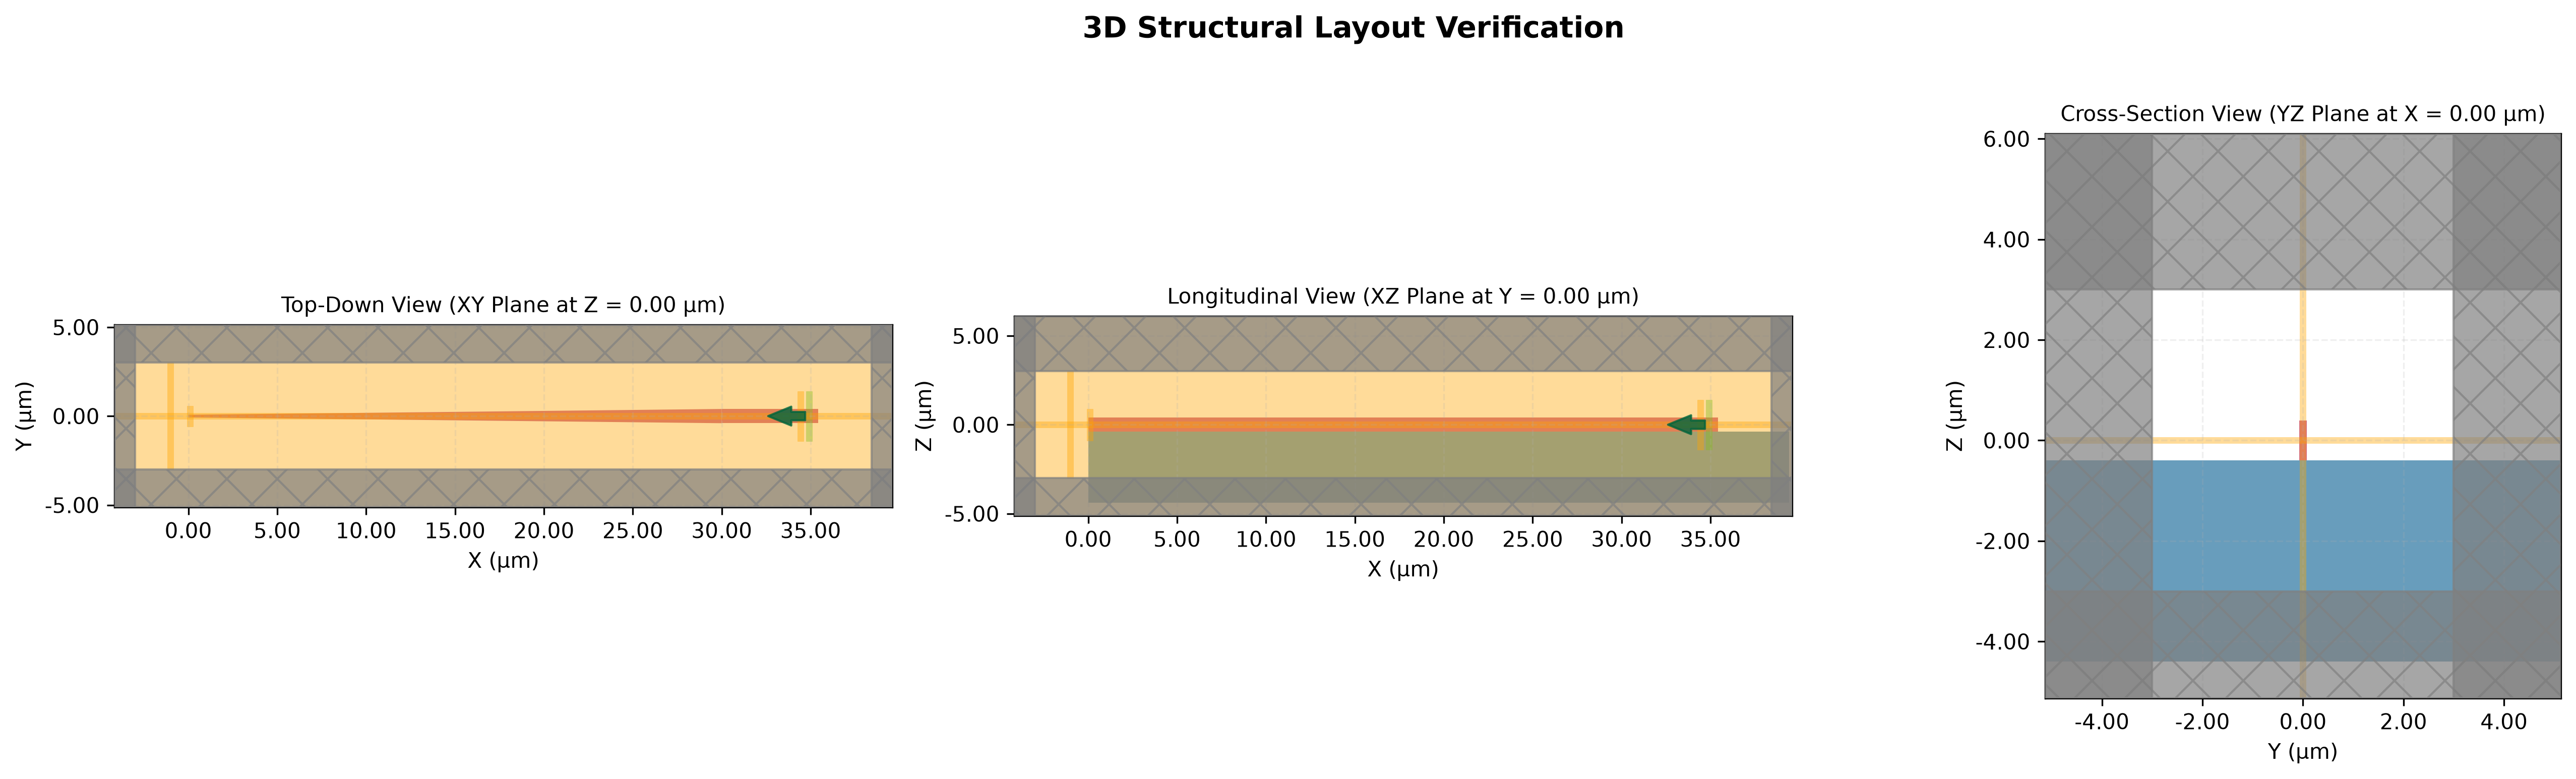

In [ ]:
# ---- Define an Arbitrary Geometry for an Out-Copupling Edge Coupler---- #
from geometries import edge_coupler

example_edge_out_coupler = edge_coupler.get_active_simulation(
    wavelength0 = 1.550,
    
    wg_width = 0.800,
    wg_height = 0.800,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    tip_width = 0.150,
    taper_length = 30,      # We keep the numbers low so we can actually see it!

    out_coupling = True,    # Declare out-coupling behavior

    fine_steps_per_wvl = 20,
    coarse_steps_per_wvl = 15


)

# Visualize 3D Geometry
from utilities.sim_plotter import display_3d

display_3d(
    device = example_edge_out_coupler,
    output_path = "example_results/edge_coupler/example_edge__out_coupler.png",
    save = True,
    coordinates = edge_coupler.get_optimal_plot_coords(example_edge_out_coupler.sim)
)

In [ ]:
# ---- Define an Arbitrary Geometry for an In-Copupling Edge Coupler---- #
from geometries import edge_coupler

example_edge_in_coupler = edge_coupler.get_active_simulation(
    wavelength0 = 1.550,
    
    wg_width = 0.800,
    wg_height = 0.800,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    tip_width = 0.150,
    taper_length = 30,  # We keep the numbers low so we can actually see it!

    in_coupling = True # Declare in-coupling behavior
)

# Visualize 3D Geometry
from utilities.sim_plotter import display_3d

display_3d(
    device = example_edge_in_coupler,
    output_path = "example_results/edge_coupler/example_edge__out_coupler.png",
    save = True,
    coordinates = edge_coupler.get_optimal_plot_coords(example_edge_in_coupler.sim)
)

## Edge Coupler Methods

In [5]:
# ---- Compute and extract mode coupling efficiency ---- #
output_dir = "example_results/edge_coupler"

efficiency = example_edge_out_coupler.get_efficiency(
    output_dir=output_dir,
    verbose=True
)

print(f"\nCalculated Coupling Efficiency: {efficiency * 100.0:.2f}%")

2026-09-06 23:39:08,001 - edgeCoupler.edge_coupler - INFO - [Profiler] Cache miss. Uploading coupler_Wtip0.15um_Ltaper30.00um_outcouple_sym000_1.550um_c7d5aad9 to Tidy3D cloud infrastructure...


23:39:08 IST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=620464;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e8127be6-f3a7-448d-9e8b-6100b9b21a85\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=620465;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e8127be6-f3a7-448d-9e8b-6100b9b21a85\taskId]8;;\]8;id=620464;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e8127be6-f3a7-448d-9e8b-6100b9b21a85\=]8;;\]8;id=620466;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e8127be6-f3a7-448d-9e8b-6100b9b21a85\fdve]8;;\]8;id=620464;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e8127be6-f3a7-448d-9e8b-6100b9b21a85\-e8127be6-f3a]8;;\
             ]8;id=620464;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e8127be6-f3a7-448d-9e8b-6100b9b21a85\7-448d-9e8b-6100b9b21a85']8;;\.

2026-09-06 23:39:08,149 - edgeCoupler.edge_coupler - INFO - [Profiler] Execution complete. Serializing data to example_results/edge_coupler/coupler_Wtip0.15um_Ltaper30.00um_outcouple_sym000_1.550um_c7d5aad9/raw_simulation_data.hdf5...
2026-09-06 23:39:08,199 - edgeCoupler.edge_coupler - INFO - [Analytics] Extracting transmission metrics from 'flux_fiber'...
2026-09-06 23:39:08,201 - edgeCoupler.edge_coupler - INFO - [Analytics] Transmission evaluation complete. Efficiency: 73.62%

Calculated Coupling Efficiency: 73.62%


In [ ]:
# ---- Extract Insertion Loss in dB ---- #
loss_db = example_edge_out_coupler.get_loss_db(
    output_dir=output_dir,
    verbose=False
)

print(f"Calculated Insertion Loss: {loss_db:.2f} dB")

In [ ]:
# ---- Plot spatial field intensity distributions across XY and XZ cross-sections ---- #
# XY Plane (Top-down view along propagation axis)
example_edge_out_coupler.plot_fields(
    output_dir=output_dir,
    monitor_name="field_xy",
    save=True,
    show=True
)

# XZ Plane (Side cross-section through core center)
example_edge_out_coupler.plot_fields(
    output_dir=output_dir,
    monitor_name="field_xz",
    save=True,
    show=True
)

### Edge-Coupler Optimization

Initializing 25 simulations for the sweep...
Submitting batch to Tidy3D cloud infrastructure...


17:27:00 IST Got 9 simulations from cache.

/home/esraaj/miniforge3/envs/tarang-env/lib/python3.11/site-packages/rich/live.p
y:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2026-09-06 17:27:03,003 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 10
2026-09-06 17:27:03,081 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 10
2026-09-06 17:27:03,082 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 10
2026-09-06 17:27:03,086 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 10
2026-09-06 17:27:03,881 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 10
2026-09-06 17:27:04,189 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 10
2026-09-06 17:27:07,10

17:27:09 IST Started working on Batch containing 25 tasks.

2026-09-06 17:27:10,130 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 9
2026-09-06 17:27:10,257 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 9
2026-09-06 17:27:10,605 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 10
2026-09-06 17:27:10,745 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 10
2026-09-06 17:27:10,757 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 10
2026-09-06 17:27:10,758 - urllib3.connectionpool - WARNING - Connection pool is full, discarding connection: tidy3d-api.simulation.cloud. Connection pool size: 10


17:27:37 IST Maximum FlexCredit cost: 5.147 for the whole batch.

             Use 'Batch.real_cost()' to get the billed FlexCredit cost after    
             completion.

/home/esraaj/miniforge3/envs/tarang-env/lib/python3.11/site-packages/rich/live.p
y:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

17:28:08 IST Batch complete.

2026-09-06 17:28:32,301 - edgeCoupler.edge_coupler - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/edge_coupler_sweep/coupler_Wtip0.10um_Ltaper10.00um_outcouple_sym000_1.550um_a2ca4474/raw_simulation_data.hdf5...
2026-09-06 17:28:32,558 - edgeCoupler.edge_coupler - INFO - [Analytics] Extracting transmission metrics from 'flux_fiber'...
2026-09-06 17:28:32,559 - edgeCoupler.edge_coupler - INFO - [Analytics] Transmission evaluation complete. Efficiency: 87.88%
2026-09-06 17:28:32,562 - edgeCoupler.edge_coupler - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/edge_coupler_sweep/coupler_Wtip0.15um_Ltaper10.00um_outcouple_sym000_1.550um_9f4c9335/raw_simulation_data.hdf5...
2026-09-06 17:28:32,599 - edgeCoupler.edge_coupler - INFO - [Analytics] Extracting transmission metrics from 'flux_fiber'...
2026-09-06 17:28:32,600 - edgeCoupler.edge_coupler - INFO - [Analytics] Transmission evaluation complete. Efficiency: 89.89%


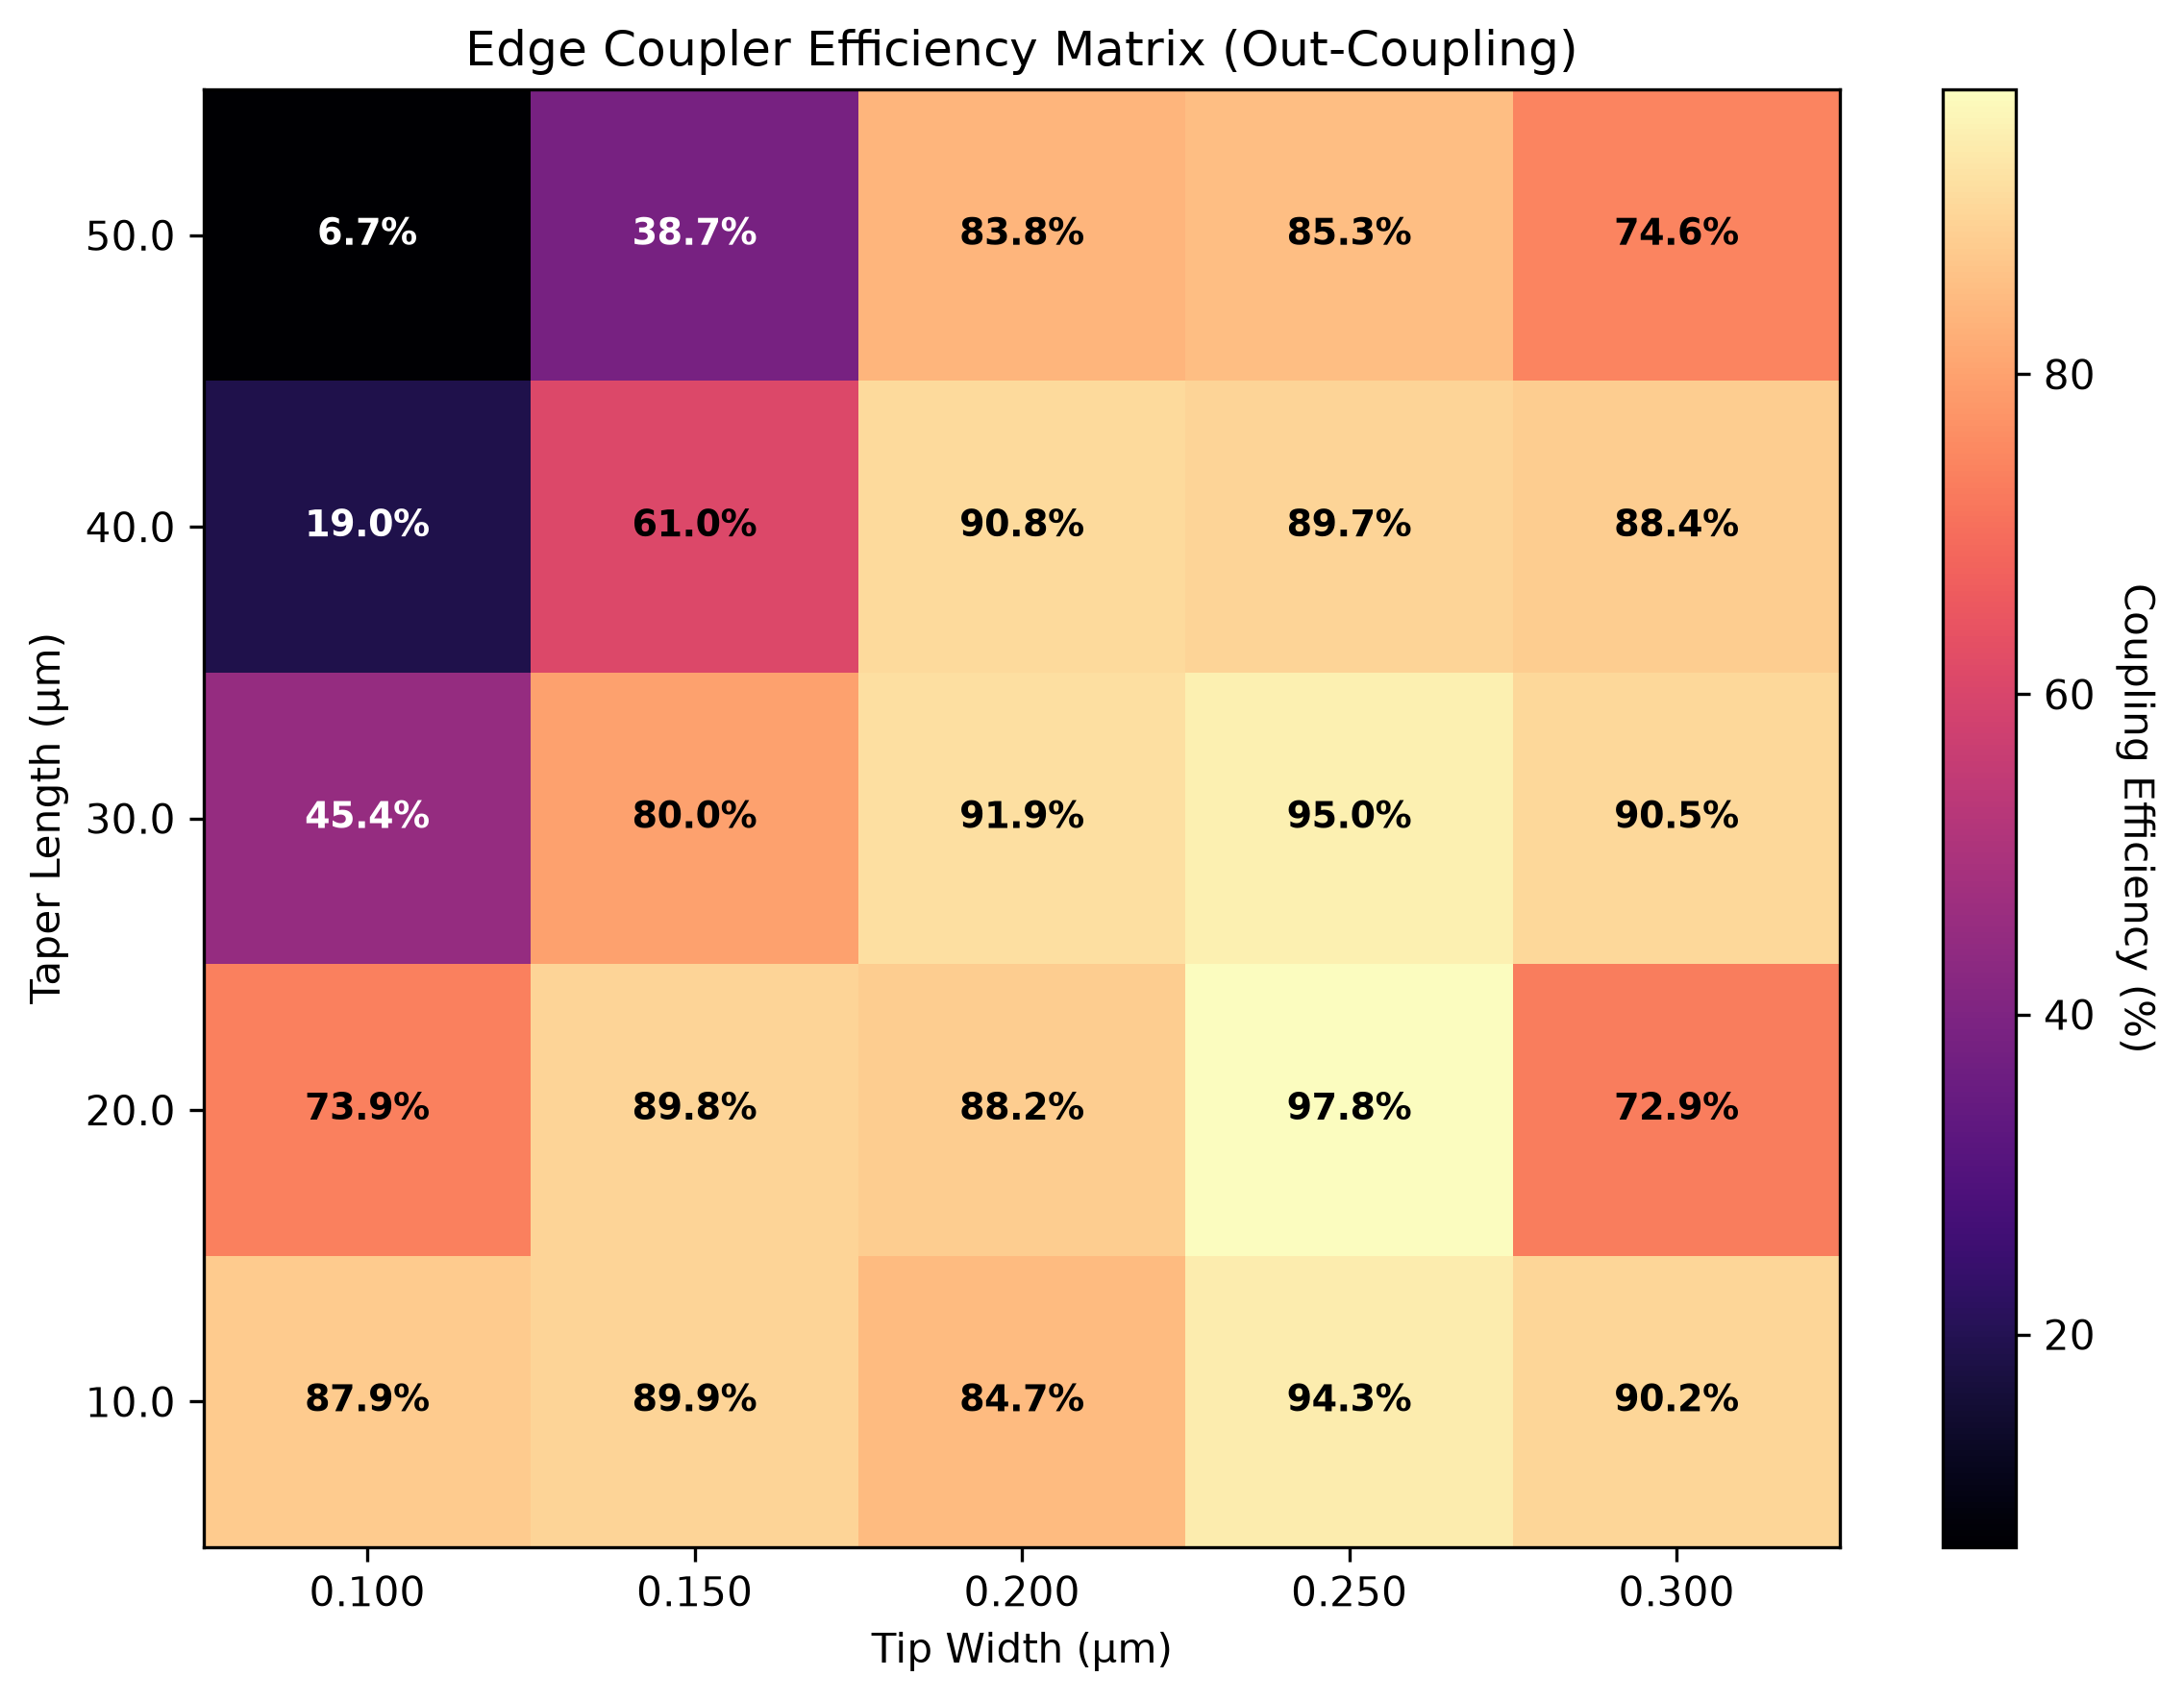


Efficiency Matrix (%):
[[87.88 89.89 84.66 94.32 90.24]
 [73.94 89.83 88.21 97.79 72.9 ]
 [45.39 79.97 91.93 94.98 90.5 ]
 [19.03 60.97 90.81 89.75 88.39]
 [ 6.7  38.72 83.78 85.34 74.64]]


In [ ]:
# ---- 2D Parametric Optimization Sweep (Out-Coupling) ---- #
from edgeCoupler import parametric_optimization_sweep
import numpy as np

# Small 3x3 parameter grid with coarse meshing for a quick test run
sweep_taper_lengths = [10.0, 20.0, 30.0, 40.0, 50.0]  # μm
sweep_tip_widths = [0.100, 0.150, 0.200, 0.250, 0.300]  # μm

efficiency_matrix = parametric_optimization_sweep(
    sweep_taper_lengths=sweep_taper_lengths,
    sweep_tip_widths=sweep_tip_widths,
    output_dir="example_results/edge_coupler/edge_coupler_sweep",
    
    wg_width=0.800,
    wg_height=0.800,
    core_medium=Si3N4,
    substrate_medium=SiO2,
    wavelength0=1.550,
    
    out_coupling=True,
    fine_steps_per_wvl=15,
    coarse_steps_per_wvl=10,
    
    batching=True,
    show=True,
    save=True
)

print("\nEfficiency Matrix (%):")
print(np.round(efficiency_matrix * 100.0, 2))

2026-09-06 23:45:52,153 - edgeCoupler.edge_coupler - INFO - [Profiler] Cache miss. Uploading coupler_Wtip0.25um_Ltaper20.00um_outcouple_sym000_1.550um_9626c58a to Tidy3D cloud infrastructure...


23:45:52 IST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=620483;https://tidy3d.simulation.cloud/workbench?taskId=fdve-54cb0af8-88aa-48d5-867d-a40f46b3bada\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=620484;https://tidy3d.simulation.cloud/workbench?taskId=fdve-54cb0af8-88aa-48d5-867d-a40f46b3bada\taskId]8;;\]8;id=620483;https://tidy3d.simulation.cloud/workbench?taskId=fdve-54cb0af8-88aa-48d5-867d-a40f46b3bada\=]8;;\]8;id=620485;https://tidy3d.simulation.cloud/workbench?taskId=fdve-54cb0af8-88aa-48d5-867d-a40f46b3bada\fdve]8;;\]8;id=620483;https://tidy3d.simulation.cloud/workbench?taskId=fdve-54cb0af8-88aa-48d5-867d-a40f46b3bada\-54cb0af8-88a]8;;\
             ]8;id=620483;https://tidy3d.simulation.cloud/workbench?taskId=fdve-54cb0af8-88aa-48d5-867d-a40f46b3bada\a-48d5-867d-a40f46b3bada']8;;\.

2026-09-06 23:45:52,283 - edgeCoupler.edge_coupler - INFO - [Profiler] Execution complete. Serializing data to example_results/edger_coupler/optimized_edge_coupler/coupler_Wtip0.25um_Ltaper20.00um_outcouple_sym000_1.550um_9626c58a/raw_simulation_data.hdf5...
2026-09-06 23:45:52,442 - edgeCoupler.edge_coupler - INFO - [Analytics] Extracting transmission metrics from 'flux_fiber'...
2026-09-06 23:45:52,446 - edgeCoupler.edge_coupler - INFO - [Analytics] Transmission evaluation complete. Efficiency: 94.11%
2026-09-06 23:45:52,453 - edgeCoupler.edge_coupler - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/edger_coupler/optimized_edge_coupler/coupler_Wtip0.25um_Ltaper20.00um_outcouple_sym000_1.550um_9626c58a/raw_simulation_data.hdf5...
2026-09-06 23:45:52,546 - edgeCoupler.edge_coupler - INFO - [Analytics] Extracting transmission metrics from 'flux_fiber'...
2026-09-06 23:45:52,549 - edgeCoupler.edge_coupler - INFO - [Analytics] Transmission evaluation co

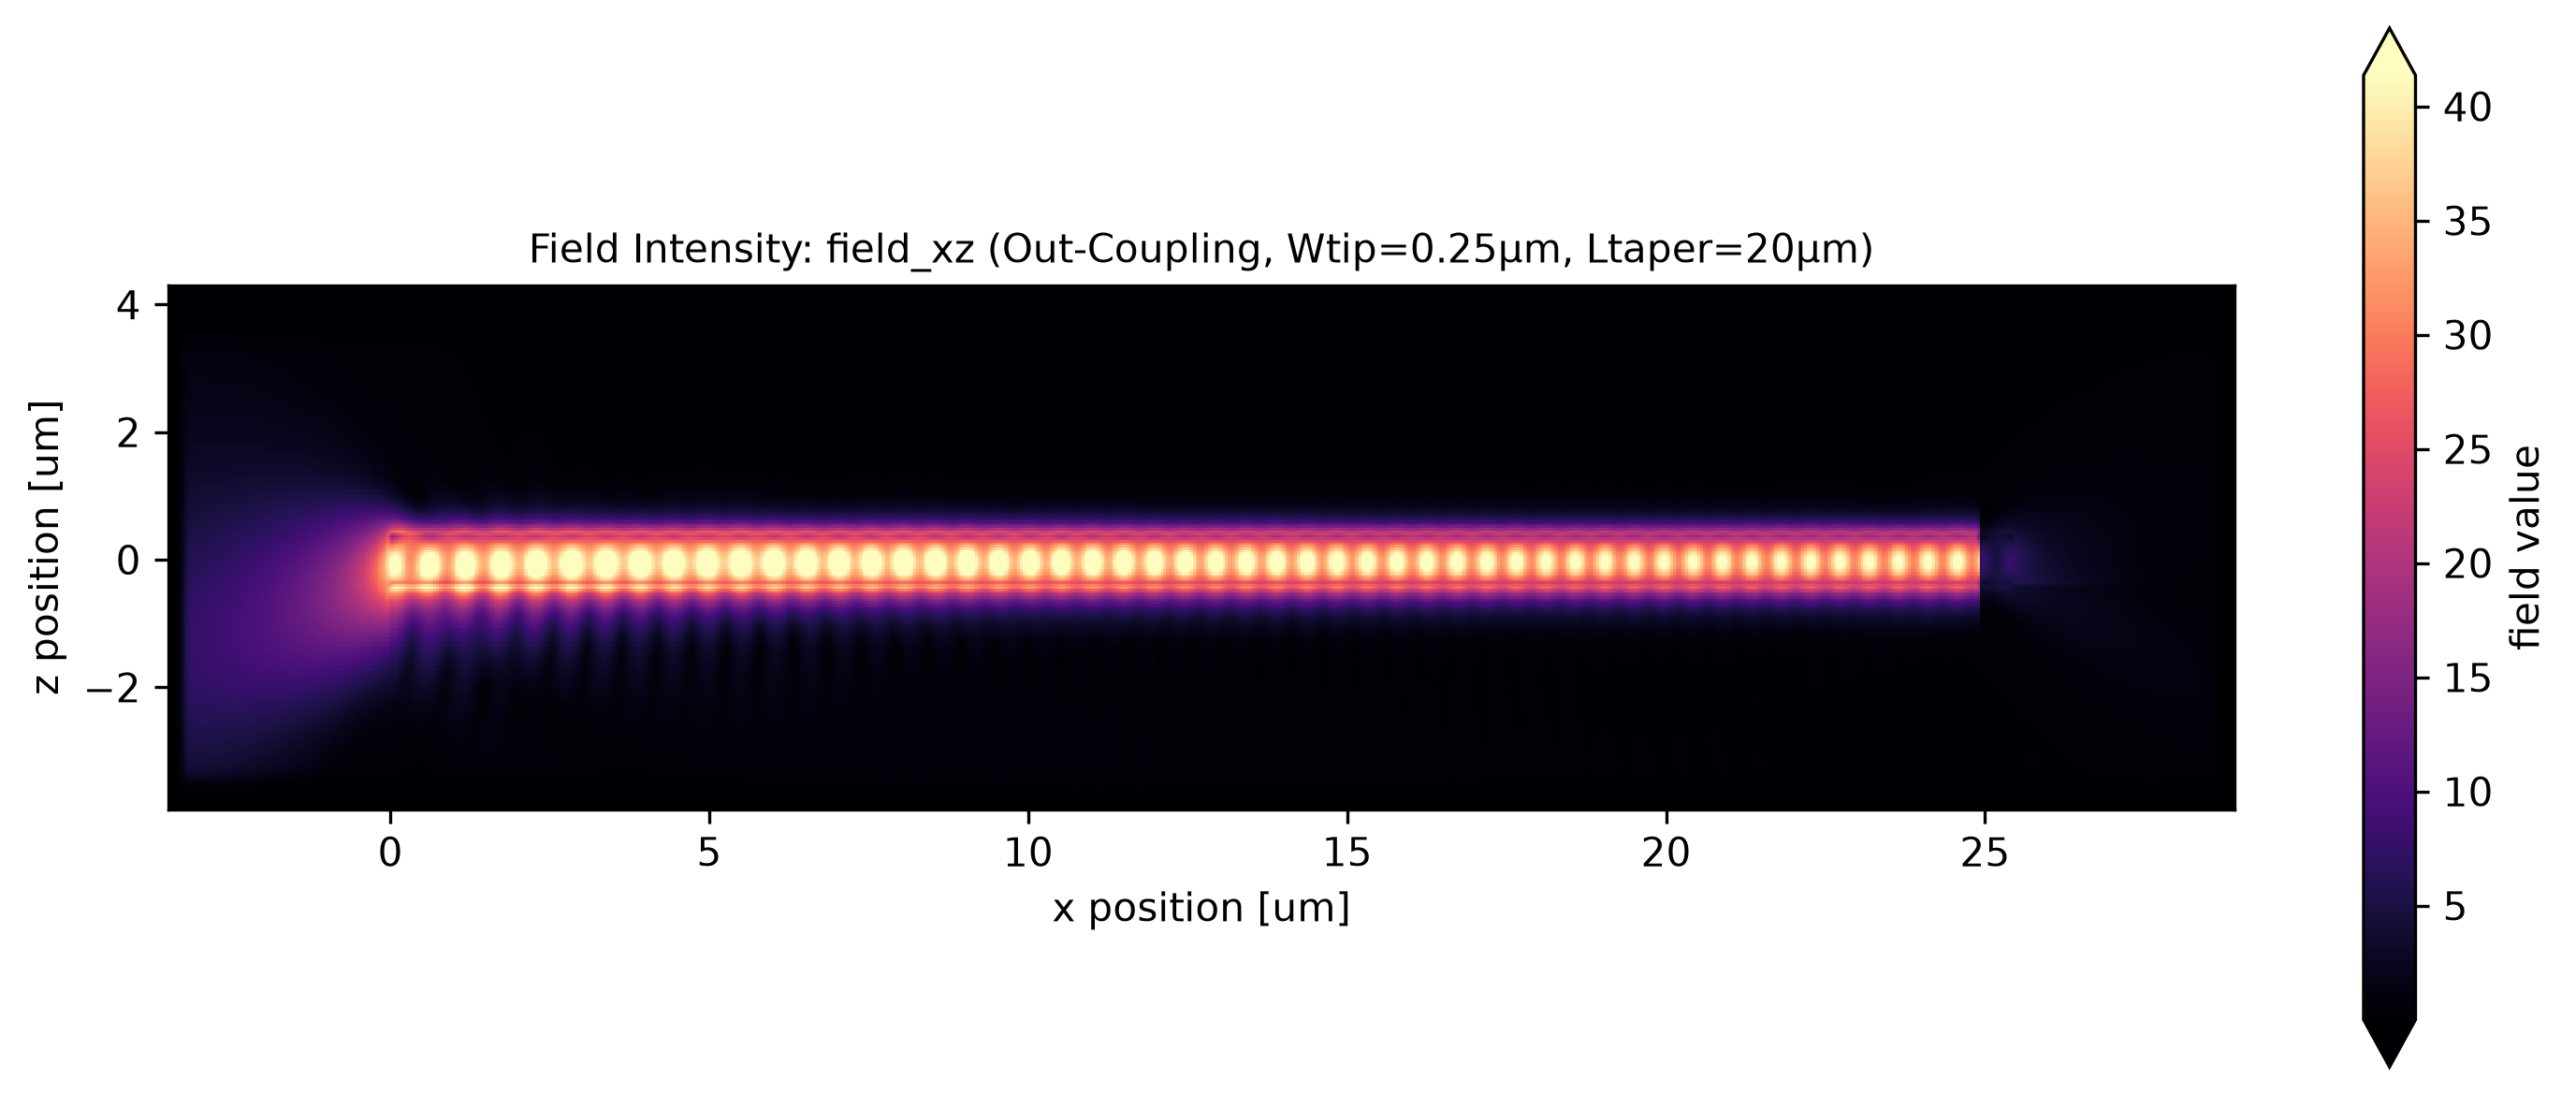


Calculated Coupling Efficiency: 94.11%
Calculated Insertion Loss: 0.26 dB


In [9]:
# ---- Test the Optimized Edge Coupler ---- #
from pathlib import Path
from geometries import edge_coupler

results_dir = Path("example_results/edger_coupler/optimized_edge_coupler/")

optimized_edge_coupler = edge_coupler.get_active_simulation(
    wavelength0 = 1.550,
    
    wg_width = 0.800,
    wg_height = 0.800,

    core_medium = Si3N4,
    substrate_medium = SiO2,

    # Use the numbers from the previous cell
    tip_width = 0.250,
    taper_length = 20,

    out_coupling = True,    # Declare out-coupling behavior

    # Meshing (higher resolution this time)
    fine_steps_per_wvl = 20,
    coarse_steps_per_wvl = 15
)

# Get efficiency (high resolution simulation)
optimized_efficiency : float = optimized_edge_coupler.get_efficiency(
    output_dir = results_dir,
    verbose = True
)

# Get loss
optimized_loss_db : float = optimized_edge_coupler.get_loss_db(
    output_dir = results_dir,
    verbose = True
)

# Get field plots
optimized_edge_coupler.plot_fields(
    output_dir=results_dir,
    monitor_name="field_xz",
    save=True,
    show=True
)

# Print Results
print(f"\nCalculated Coupling Efficiency: {optimized_efficiency * 100.0:.2f}%")
print(f"Calculated Insertion Loss: {optimized_loss_db:.2f} dB")